# HW2 Part 1: Data Cleaning & Validation

This notebook turns the intentionally dirty `ohlc_hw` table into `ohlc_hw_cleaned`, the input for the
single-stock report (`02_stock_report_template.ipynb`) and the batch runner (`03_run_all_stocks.py`).

**Workflow**

1. **Load and inspect** the raw table.
2. **Detect** every data quality issue with small, reusable functions, and collect them in one *Data Quality
   Report*. This is the diagnosis *before* any repair.
3. **Test** the detectors and repairs on small injected examples, covering the cases this database doesn't contain.
4. **Clean** with a pipeline of functions, one per issue. Every repair leaves a `flag_*` column. Rows that can't be
   repaired defensibly are **quarantined** with a reason, not guessed.
5. **Validate**: rerun the checks on the result, account for every raw row, and save to the database.

All per-ticker logic (returns, filling, interpolation) runs **within each ticker, sorted by date**, so one
stock never borrows another stock's value. The raw `ohlc_hw` table is never modified.

In [1]:
import sqlite3
from contextlib import closing
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 25)
pd.set_option("display.max_colwidth", 90)

DB_PATH = Path("data/data.db")      # local working copy; never committed
RAW_TABLE = "ohlc_hw"
REFERENCE_TABLE = "ohlc"            # supplied clean table: reference calendar and adjustment factors
CLEAN_TABLE = "ohlc_hw_cleaned"
QUARANTINE_TABLE = "ohlc_hw_quarantine"
REPORT_TABLE = "ohlc_hw_quality_report"
AUDIT_TABLE = "ohlc_hw_ticker_audit"

PRICE_COLS = ["open", "high", "low", "close"]   # raw prices
ALL_PRICE_COLS = PRICE_COLS + ["adj_close"]      # raw + vendor-adjusted
RAW_COLUMNS = ["ts", *ALL_PRICE_COLS, "volume", "ticker"]

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"{DB_PATH.resolve()} not found. Copy data.db from bCourses into a data/ folder next to this notebook."
    )


def read_sql(query: str, parse_dates=("ts",)) -> pd.DataFrame:
    """Run a read-only query against the homework database and return a DataFrame."""
    with closing(sqlite3.connect(f"{DB_PATH.resolve().as_uri()}?mode=ro", uri=True)) as conn:
        return pd.read_sql_query(query, conn, parse_dates=list(parse_dates))

## 1.1 Load and inspect the data

In [2]:
raw = read_sql(f"SELECT * FROM {RAW_TABLE}")
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   ts         397711 non-null  datetime64[us]
 1   open       397711 non-null  float64       
 2   high       397711 non-null  float64       
 3   low        397711 non-null  float64       
 4   close      397711 non-null  float64       
 5   adj_close  377856 non-null  float64       
 6   volume     397711 non-null  int64         
 7   ticker     397711 non-null  str           
dtypes: datetime64[us](1), float64(5), int64(1), str(1)
memory usage: 27.9 MB


In [3]:
raw.describe().T

,count,mean,min,25%,50%,75%,max,std
ts,397711,1998-04-17 21:18:45.292486,1962-01-02 00:00:00,1985-05-28 00:00:00,2000-01-06 00:00:00,2012-08-21 00:00:00,2024-12-06 00:00:00,NaN
open,397711.0,46.285479,0.0,4.209938,19.85,57.53,604.26,67.132594
high,397711.0,46.74766,0.005208,4.24,20.06,58.13,608.63,67.77821
low,397711.0,45.816279,0.004801,4.16,19.63,56.95,597.88,66.477178
close,397711.0,46.292903,0.005208,4.2,19.86,57.53,605.4,67.141879
adj_close,377856.0,51.65225,0.002945,1.39,11.96,43.77,10442.510783,194.584045
volume,397711.0,30977733.689946,0.0,1730700.0,4648200.0,11023796.5,9276606399.0,126623650.175253


**Columns**

| Column | Meaning |
|---|---|
| `ts` | Observation (trading) date |
| `ticker` | Stock symbol |
| `open`, `high`, `low`, `close` | Raw daily prices: first trade, highest, lowest and last trade of the day |
| `adj_close` | Vendor-adjusted close, corrected for splits and dividends so returns across those events are comparable |
| `volume` | Number of shares traded that day |

`adj_close / close` is the **adjustment factor**. It changes slowly, stepping only on dividend and split dates,
which makes it a useful consistency check. Raw OHLC bounds (`low <= close <= high`) don't apply to `adj_close`.

In [4]:
print(f"Date range: {raw['ts'].min():%Y-%m-%d} to {raw['ts'].max():%Y-%m-%d}")
print(f"Rows: {len(raw):,}")
print(f"Distinct ticker labels: {raw['ticker'].nunique()}")
raw["ticker"].drop_duplicates().sort_values().head(6).tolist()

Date range: 1962-01-02 to 2024-12-06
Rows: 397,711
Distinct ticker labels: 150


['<a target="_blank"><span style="color: blue">AAPL</span></a>',
 '<a target="_blank"><span style="color: blue">AMGN</span></a>',
 '<a target="_blank"><span style="color: blue">AMZN</span></a>',
 '<a target="_blank"><span style="color: blue">AXP</span></a>',
 '<a target="_blank"><span style="color: blue">BA</span></a>',
 '<a target="_blank"><span style="color: blue">CAT</span></a>']

The first surprise: there seem to be 150 tickers, but many labels are **HTML fragments** such as
`<a ...><span style="color: blue">AAPL</span></a>`, probably copied out of a web page. Tickers must be
normalized (markup, whitespace and case) before any grouping or de-duplication.

## 1.2 Detect data quality issues

Every detector returns rows in the same *Data Quality Report* format,
`ticker | issue_type | issue_date | description | severity`. One observation can have several issues.

### Structural issues: ticker labels and duplicates

In [5]:
REPORT_COLS = ["ticker", "issue_type", "issue_date", "description", "severity"]


def make_issues(rows: pd.DataFrame, issue_type: str, description, severity, date_col="ts") -> pd.DataFrame:
    """Build Data Quality Report rows from the offending rows.

    `description` and `severity` can be a single value or one value per row.
    Pass date_col=None for issues that are not tied to a single date.
    """
    n = len(rows)
    return pd.DataFrame({
        "ticker": rows["ticker"].to_numpy(),
        "issue_type": [issue_type] * n,
        "issue_date": rows[date_col].to_numpy() if date_col else [pd.NaT] * n,
        "description": description if not isinstance(description, str) else [description] * n,
        "severity": severity if not isinstance(severity, str) else [severity] * n,
    }, columns=REPORT_COLS)


def clean_ticker_symbol(ticker: pd.Series) -> pd.Series:
    """Normalize ticker labels: strip HTML tags and whitespace, upper-case. '<a ...><span ...> aapl</span></a>' -> 'AAPL'."""
    return ticker.str.replace(r"<[^>]+>", "", regex=True).str.strip().str.upper()


def ticker_label_audit(df: pd.DataFrame) -> pd.DataFrame:
    """Every original ticker label, the symbol it normalizes to, and how many raw rows use it."""
    return (df.assign(symbol=clean_ticker_symbol(df["ticker"]))
            .groupby(["symbol", "ticker"]).size().rename("n_rows").reset_index()
            .rename(columns={"ticker": "original_label"}))


def detect_ticker_format_issues(df: pd.DataFrame) -> pd.DataFrame:
    """One report row per symbol whose rows are stored under non-normalized labels."""
    symbol = clean_ticker_symbol(df["ticker"])
    bad = df["ticker"] != symbol
    summary = (df[bad].assign(symbol=symbol[bad]).groupby("symbol")
               .agg(n_rows=("ticker", "size"), n_labels=("ticker", "nunique")).reset_index())
    descriptions = [f"{r.n_rows} rows stored under {r.n_labels} non-normalized labels of '{r.symbol}'"
                    for r in summary.itertuples()]
    return make_issues(summary.rename(columns={"symbol": "ticker"}), "ticker_format", descriptions, "high", date_col=None)


def detect_duplicates(df: pd.DataFrame) -> pd.DataFrame:
    """Report exact duplicate rows (per ticker) and conflicting rows that share a ticker/date.

    Expects normalized tickers, so copies stored under different labels are caught.
    """
    exact = df.duplicated(keep="first")
    per_ticker = df[exact].groupby("ticker").size().reset_index(name="n")
    issues = [make_issues(per_ticker, "duplicate_row", [f"{n} exact duplicate rows" for n in per_ticker["n"]],
                          "medium", date_col=None)]
    deduped = df[~exact]
    conflicts = deduped[deduped.duplicated(["ticker", "ts"], keep=False)].drop_duplicates(["ticker", "ts"])
    issues.append(make_issues(conflicts, "conflicting_duplicate",
                              "Several rows with different values share this ticker/date", "high"))
    return pd.concat(issues, ignore_index=True)


ticker_audit = ticker_label_audit(raw)
standardized = raw.assign(ticker=clean_ticker_symbol(raw["ticker"]))
is_relabelled = raw["ticker"] != standardized["ticker"]
plain_keys = pd.MultiIndex.from_frame(standardized.loc[~is_relabelled, ["ticker", "ts"]])
relabelled_keys = pd.MultiIndex.from_frame(standardized.loc[is_relabelled, ["ticker", "ts"]]).unique()
deduped = standardized.drop_duplicates()

print(f"Symbols ({standardized['ticker'].nunique()}): {', '.join(sorted(standardized['ticker'].unique()))}")
print(f"Rows under non-normalized labels: {is_relabelled.sum():,}, of which "
      f"{len(relabelled_keys.difference(plain_keys)):,} ticker/dates exist only under such a label")
print(f"Exact duplicate rows: {standardized.duplicated().sum():,}")
print(f"Conflicting ticker/date keys after removing exact duplicates: "
      f"{deduped.duplicated(['ticker', 'ts']).sum()}")
ticker_audit.head(6)

Symbols (30): AAPL, AMGN, AMZN, AXP, BA, CAT, CRM, CSCO, CVX, DIS, GS, HD, HON, IBM, JNJ, JPM, KO, MCD, MMM, MRK, MSFT, NKE, NVDA, PG, SHW, TRV, UNH, V, VZ, WMT
Rows under non-normalized labels: 39,936, of which 36,985 ticker/dates exist only under such a label
Exact duplicate rows: 29,460
Conflicting ticker/date keys after removing exact duplicates: 0


,symbol,original_label,n_rows
0,AAPL,"<a target=""_blank""><span style=""color: blue"">AAPL</span></a>",307
1,AAPL,"<a target=""_blank""><span style=""color: red"">AAPL</span></a>",318
2,AAPL,"<a target=""_blank""><span style=""font-weight: bold; color: blue"">AAPL</span></a>",306
3,AAPL,"<a target=""_blank""><span style=""font-weight: bold; color: red"">AAPL</span></a>",264
4,AAPL,AAPL,10747
5,AMGN,"<a target=""_blank""><span style=""color: blue"">AMGN</span></a>",294


The 150 labels are really **30 symbols**, each stored under five labels (plain, plus blue/red, bold or not).
Almost all rows under HTML labels are dates that exist **only** under that label, so deleting them would throw
away about 10% of the data. Instead we normalize first, then remove exact duplicates. There are **no conflicting
keys**: every repeated ticker/date is an exact copy. The full label audit is saved as `ohlc_hw_ticker_audit`.

The remaining detectors run on `base` (normalized, exact duplicates removed, sorted). This only makes the
diagnosis meaningful; the cleaning itself happens in the pipeline below.

In [6]:
base = deduped.sort_values(["ticker", "ts"]).reset_index(drop=True)
print(f"{len(base):,} unique rows for {base['ticker'].nunique()} tickers")

368,251 unique rows for 30 tickers


### Missing data

In [7]:
def detect_missing_values(df: pd.DataFrame) -> pd.DataFrame:
    """One report row per missing cell. Missing raw prices are high severity; adj_close/volume medium."""
    parts = []
    for col in ALL_PRICE_COLS + ["volume"]:
        rows = df[df[col].isna()]
        parts.append(make_issues(rows, "missing_value", f"{col} is missing",
                                 "high" if col in PRICE_COLS else "medium"))
    return pd.concat(parts, ignore_index=True)


base[RAW_COLUMNS].isna().sum().to_frame("missing cells")

,missing cells
ts,0
open,0
high,0
low,0
close,0
adj_close,18374
volume,0
ticker,0


Only `adj_close` has missing cells. **Missing trading days** are a different check: whole rows that should exist
but don't. As the reference calendar we use the supplied `ohlc` table's dates for each ticker (allowed by the
assignment), limited to that ticker's own first-to-last history. Business weekdays alone would be wrong
because they include exchange holidays.

In [8]:
def detect_missing_trading_days(df: pd.DataFrame, reference: pd.DataFrame) -> pd.DataFrame:
    """Compare each ticker's dates with a reference calendar (`ticker`, `ts`) over the ticker's own history.

    Returns one report row per gap (run of consecutive missing reference dates), with extra columns
    `n_days` and `gap_end` for summaries. No prices are invented for the missing dates.
    """
    rows = []
    for ticker, g in df.groupby("ticker"):
        ref = reference.loc[reference["ticker"] == ticker, "ts"]
        expected = pd.DatetimeIndex(ref[(ref >= g["ts"].min()) & (ref <= g["ts"].max())]).unique().sort_values()
        missing = expected.difference(pd.DatetimeIndex(g["ts"]))
        if missing.empty:
            continue
        pos = expected.get_indexer(missing)
        gap_id = np.cumsum(np.diff(pos, prepend=pos[0] - 2) != 1)  # consecutive positions = same gap
        for _, gap in pd.Series(missing).groupby(gap_id):
            start, end, n = gap.iloc[0], gap.iloc[-1], len(gap)
            rows.append({
                "ticker": ticker, "issue_type": "missing_trading_days", "issue_date": start,
                "description": f"{ticker} is missing {n} trading day(s) between {start:%Y-%m-%d} and {end:%Y-%m-%d}",
                "severity": "medium" if n >= 3 else "low", "n_days": n, "gap_end": end,
            })
    return pd.DataFrame(rows, columns=REPORT_COLS + ["n_days", "gap_end"])


def summarize_missing_days(gaps: pd.DataFrame) -> list[str]:
    """One sentence per ticker: 'Ticker X is missing Y trading days between [start] and [end]'."""
    if gaps.empty:
        return ["No missing trading days: every ticker has a row for every reference date in its history."]
    per_ticker = gaps.groupby("ticker").agg(days=("n_days", "sum"), start=("issue_date", "min"), end=("gap_end", "max"))
    return [f"Ticker {t} is missing {r.days} trading days between {r.start:%Y-%m-%d} and {r.end:%Y-%m-%d}"
            for t, r in per_ticker.iterrows()]


# Demonstration on a tiny example: a 6-day calendar with one date deliberately removed
demo_calendar = pd.DataFrame({"ticker": "DEMO", "ts": pd.bdate_range("2024-03-04", periods=6)})
demo_gaps = detect_missing_trading_days(demo_calendar.drop(index=3), demo_calendar)
print("\n".join(summarize_missing_days(demo_gaps)))
demo_gaps[REPORT_COLS]

Ticker DEMO is missing 1 trading days between 2024-03-07 and 2024-03-07


,ticker,issue_type,issue_date,description,severity
0,DEMO,missing_trading_days,2024-03-07,DEMO is missing 1 trading day(s) between 2024-03-07 and 2024-03-07,low


In [9]:
reference_dates = read_sql(f"SELECT ticker, ts FROM {REFERENCE_TABLE}")
gap_issues = detect_missing_trading_days(base, reference_dates)
print("\n".join(summarize_missing_days(gap_issues)))

No missing trading days: every ticker has a row for every reference date in its history.


The detector finds the removed date in the demo, and **zero gaps** in the real data: after normalization and
de-duplication, every ticker has a row for every reference date. That is a valid result. Nothing needs
to be invented to fill this check.

### Outliers

Daily returns use the raw `close` within each ticker: `(close - prev_close) / prev_close`. A return is flagged when
`abs(return - mean) > 3 * std` for that ticker, using the sample standard deviation (`ddof=1`) and both tails.
Undefined returns (a ticker's first day, or a missing or zero previous close) are excluded. If a ticker's standard
deviation is zero or undefined, nothing can be called extreme, so nothing is flagged.
This is a **review flag**, not a deletion rule.

In [10]:
def add_daily_returns(df: pd.DataFrame) -> pd.DataFrame:
    """Add raw (`ret`) and adjusted (`adj_ret`) simple daily returns within each ticker; non-finite returns become NaN."""
    out = df.sort_values(["ticker", "ts"]).copy()
    by_ticker = out.groupby("ticker")
    for col, name in [("close", "ret"), ("adj_close", "adj_ret")]:
        returns = by_ticker[col].pct_change()
        out[name] = returns.where(np.isfinite(returns))
    return out


def extreme_mask(df: pd.DataFrame, col: str, n_std: float = 3.0) -> pd.Series:
    """True where `col` is more than n_std sample standard deviations from its ticker's mean (both tails).

    NaN values are never flagged. Tickers with zero or undefined std flag nothing.
    """
    by_ticker = df.groupby("ticker")[col]
    mean, std = by_ticker.transform("mean"), by_ticker.transform("std", ddof=1)
    usable = df[col].notna() & std.notna() & (std > 0)
    return usable & ((df[col] - mean).abs() > n_std * std)


def detect_return_outliers(df: pd.DataFrame, n_std: float = 3.0) -> pd.DataFrame:
    """Flag daily close-to-close returns more than n_std std devs from the ticker's mean."""
    out = add_daily_returns(df)
    flagged = out[extreme_mask(out, "ret", n_std)]
    descriptions = [f"Daily return of {r:+.1%} exceeds {n_std:g} std devs" for r in flagged["ret"]]
    severity = np.where(flagged["ret"].abs() > 0.25, "medium", "low")
    return make_issues(flagged, "return_outlier", descriptions, severity)


def close_spike_mask(df: pd.DataFrame, min_jump: float = 0.4, max_round_trip: float = 0.1) -> pd.Series:
    """One-day price spikes: the close jumps by > min_jump, then the next close comes back to within
    max_round_trip of the previous close. Real repricings rarely reverse completely overnight; entry errors do."""
    by_ticker = df.groupby("ticker")["close"]
    prev_close, next_close = by_ticker.shift(1), by_ticker.shift(-1)
    jump = (df["close"] / prev_close - 1).abs()
    round_trip = (next_close / prev_close - 1).abs()
    return (jump > min_jump) & (round_trip < max_round_trip)


def detect_close_spikes(df: pd.DataFrame) -> pd.DataFrame:
    """Report one-day close spikes that reverse the next day (likely data entry errors)."""
    rows = df[close_spike_mask(df)]
    descriptions = [f"Close {c:g} is a one-day spike that reverses the next day" for c in rows["close"]]
    return make_issues(rows, "close_spike", descriptions, "high")


# Tiny check of the edge cases: a constant series has zero std, so nothing is flagged
flat = pd.DataFrame({"ticker": "FLAT", "ts": pd.bdate_range("2024-01-01", periods=5), "close": 10.0})
flat["ret"] = flat["close"].pct_change()
assert not extreme_mask(flat, "ret").any()

return_issues = detect_return_outliers(base)
spike_issues = detect_close_spikes(base)
print(f"Returns beyond 3 std devs: {len(return_issues):,}")
spike_issues

Returns beyond 3 std devs: 5,056


,ticker,issue_type,issue_date,description,severity
0,TRV,close_spike,1976-10-28,Close 9.22 is a one-day spike that reverses the next day,high
1,TRV,close_spike,1978-12-20,Close 8.03 is a one-day spike that reverses the next day,high
2,TRV,close_spike,1981-08-10,Close 12.06 is a one-day spike that reverses the next day,high


#### Investigating the extreme returns

Over 5,000 returns exceed 3 standard deviations. Daily stock returns have fat tails, so that is expected, and most
are real market moves: kept and flagged. The moves larger than ±40% get a closer look, with the day before and after:

In [11]:
with_returns = add_daily_returns(base)
big_moves = with_returns.index[with_returns["ret"].abs() > 0.4]
context = sorted({j for i in big_moves for j in (i - 1, i, i + 1)})
with_returns.loc[context, ["ticker", "ts", "open", "high", "low", "close", "adj_close", "ret"]]

,ticker,ts,open,high,low,close,adj_close,ret
4998,AAPL,2000-09-28,0.88058,0.96094,0.85937,0.95536,0.806770,0.093239
4999,AAPL,2000-09-29,0.50335,0.51786,0.45313,0.45982,0.388310,-0.518695
5000,AAPL,2000-10-02,0.47321,0.47768,0.41964,0.43304,0.365690,-0.058240
213787,MCD,1967-12-29,0.73868,0.74074,0.70988,0.70988,0.311000,-0.038988
213788,MCD,1968-01-02,0.17490,0.17490,0.17490,0.17490,0.075921,-0.753620
213789,MCD,1968-01-03,0.17567,0.17567,0.17567,0.17567,0.076256,0.004403
280844,NVDA,2000-03-06,0.12344,0.13281,0.12083,0.12188,0.111780,-0.006359
280845,NVDA,2000-03-07,0.15625,0.18177,0.14948,0.17357,0.159200,0.424106
280846,NVDA,2000-03-08,0.17347,0.17656,0.16094,0.17500,0.160510,0.008239
318331,TRV,1976-10-27,4.61000,4.61000,4.61000,4.61000,13.883250,0.024444


We record what the data shows and say where we are uncertain:

- **TRV (1976, 1978, 1981)**: the price exactly doubles for one day, with open = high = low = close, then returns
  to the previous level. A full reversal of a +100% move is strong evidence of a **data error** (`close_spike`).
  These rows are interpolated between their valid neighbours.
- **AAPL, 2000-09-29 (−52%)**: the drop persists on the following days, and the adjusted series agrees. This is
  consistent with a genuine repricing. (A profit warning was widely reported around this date, but that can't be
  verified from this dataset.) Kept and flagged.
- **NVDA, 2000-03-07 (+42%)**: the move persists the next day. Consistent with a genuine move, so kept and flagged.
- **MCD, 1968-01-02 (−75%)**: raw *and* adjusted prices both drop and stay down. A ratio of almost exactly 1/4
  *could* be an unadjusted split, but nothing in the data confirms it, so we neither rescale nor delete it.
  It is kept, flagged for review, and lies decades outside the report window.

The spike rule (jump above 40% **and** a near-complete reversal) is deliberately strict. With looser
thresholds, Black Monday (October 1987: drops of 20–30% with partial rebounds) would be mistaken for data errors.

### Impossible prices and other inconsistencies

In [12]:
PRICE_RULES = {
    "high < close": lambda d: d["high"] < d["close"],
    "low > close": lambda d: d["low"] > d["close"],
    "open > high": lambda d: d["open"] > d["high"],
    "open < low": lambda d: d["open"] < d["low"],
    "high < low": lambda d: d["high"] < d["low"],
}


def detect_price_relationship_issues(df: pd.DataFrame) -> pd.DataFrame:
    """Check the raw OHLC bounds: low <= open <= high and low <= close <= high."""
    parts = []
    for rule, check in PRICE_RULES.items():
        rows = df[check(df)]
        descriptions = [f"{rule}: O={r.open:g} H={r.high:g} L={r.low:g} C={r.close:g}" for r in rows.itertuples()]
        parts.append(make_issues(rows, "impossible_price", descriptions, "high"))
    return pd.concat(parts, ignore_index=True)


def detect_invalid_prices(df: pd.DataFrame) -> pd.DataFrame:
    """Nonpositive or non-finite values in any price column, adj_close included. (NaN is reported as missing.)"""
    parts = []
    for col in ALL_PRICE_COLS:
        values = df[col]
        rows = df[values.notna() & (~np.isfinite(values) | (values <= 0))]
        descriptions = [f"{col} = {v:g} is not a positive finite price" for v in rows[col]]
        parts.append(make_issues(rows, "invalid_price", descriptions, "high"))
    return pd.concat(parts, ignore_index=True)


def detect_volume_issues(df: pd.DataFrame) -> pd.DataFrame:
    """Negative or non-finite volume (high), and zero-volume days (low; stale if O=H=L=C as well)."""
    volume = df["volume"]
    invalid = df[volume.notna() & (~np.isfinite(volume) | (volume < 0))]
    zero = df[volume == 0]
    flat = (zero["open"] == zero["high"]) & (zero["high"] == zero["low"]) & (zero["low"] == zero["close"])
    return pd.concat([
        make_issues(invalid, "invalid_volume", [f"volume = {v:g}" for v in invalid["volume"]], "high"),
        make_issues(zero, "zero_volume", np.where(flat, "Volume is 0 and O=H=L=C (stale quote)", "Volume is 0"), "low"),
    ], ignore_index=True)


def detect_weekend_dates(df: pd.DataFrame) -> pd.DataFrame:
    """Rows dated on a Saturday or Sunday, when US exchanges are closed."""
    rows = df[df["ts"].dt.day_of_week >= 5]
    return make_issues(rows, "weekend_date", [f"Trade dated on a {d:%A}" for d in rows["ts"]], "medium")


def adj_close_spike_mask(df: pd.DataFrame, window: int = 11, threshold: float = 2.0) -> pd.Series:
    """Corrupted adj_close values: the adjustment factor (adj_close / close) is more than `threshold` times
    away from the rolling median of the surrounding `window` days. The true factor moves only by small steps
    (dividends), or by a split ratio together with the raw close, so a jump like this means a bad value."""
    factor = df["adj_close"] / df["close"]
    local_median = factor.groupby(df["ticker"]).transform(
        lambda s: s.rolling(window, center=True, min_periods=3).median())
    ratio = factor / local_median
    return (ratio > threshold) | (ratio < 1 / threshold)


def detect_adj_close_spikes(df: pd.DataFrame) -> pd.DataFrame:
    """Report adj_close values inconsistent with the ticker's adjustment factor."""
    rows = df[adj_close_spike_mask(df)]
    descriptions = [f"adj_close {a:g} is {a / c:.1f}x the raw close {c:g}" for a, c in zip(rows["adj_close"], rows["close"])]
    return make_issues(rows, "adj_close_spike", descriptions, "high")


pd.concat([detect_price_relationship_issues(base), detect_invalid_prices(base)], ignore_index=True)

,ticker,issue_type,issue_date,description,severity
0,CVX,impossible_price,1962-01-02,open < low: O=0 H=3.3 L=3.24 C=3.3,high
1,JNJ,impossible_price,1962-01-02,open < low: O=0 H=0.22338 L=0.22222 C=0.22338,high
2,MCD,impossible_price,1966-07-05,open < low: O=0 H=0.27366 L=0.26749 C=0.26955,high
3,MRK,impossible_price,1962-01-02,open < low: O=0 H=0.39703 L=0.39317 C=0.39537,high
4,PG,impossible_price,1962-01-02,open < low: O=0 H=1.44 L=1.42 C=1.43,high
5,CVX,invalid_price,1962-01-02,open = 0 is not a positive finite price,high
6,JNJ,invalid_price,1962-01-02,open = 0 is not a positive finite price,high
7,MCD,invalid_price,1966-07-05,open = 0 is not a positive finite price,high
8,MRK,invalid_price,1962-01-02,open = 0 is not a positive finite price,high
9,PG,invalid_price,1962-01-02,open = 0 is not a positive finite price,high


- **Raw OHLC bounds**: `high < close` and `low > close` never occur. The only violations are five rows with
  `open = 0`, each on that ticker's first day in the data (1962–66). The open was evidently never recorded.
- **Invalid prices**: the same five zero opens. No negative or infinite prices, and no nonpositive `adj_close`.
- **Zero volume** days are almost all in 1962–1982 with open = high = low = close: old, stale quotes.
- **Weekend dates** occur only in 1974–75. The prices look plausible, so we keep and flag them rather than guess
  which weekday they belong to.
- **`adj_close` spikes**: about 10,000 values are 4–24× the raw close, although the true factor never exceeds 1.
  These would create huge fake returns in the reports.

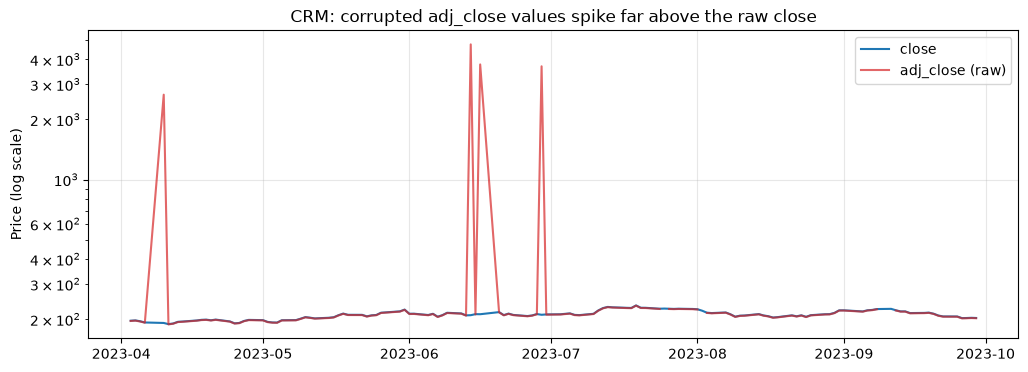

In [13]:
fig, ax = plt.subplots(figsize=(12, 4))
example = base[base["ticker"] == "CRM"].set_index("ts").loc["2023-04":"2023-09"]
ax.plot(example.index, example["close"], label="close", color="tab:blue")
ax.plot(example.index, example["adj_close"], label="adj_close (raw)", color="tab:red", alpha=0.7)
ax.set_yscale("log")
ax.set_title("CRM: corrupted adj_close values spike far above the raw close")
ax.set_ylabel("Price (log scale)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

### The Data Quality Report

`run_all_detectors` runs every check above on a raw table, so the same diagnosis can be repeated after cleaning
(and on the injected examples below).

**Severity choices**

| Severity | Issue types | Why |
|---|---|---|
| **high** | `ticker_format`, `conflicting_duplicate`, `impossible_price`, `invalid_price`, `invalid_volume`, `close_spike`, `adj_close_spike`, missing raw price | The value is wrong and would corrupt grouping, returns or risk metrics if used as-is |
| **medium** | `duplicate_row`, missing `adj_close`/`volume`, `weekend_date`, gaps of 3+ trading days, returns beyond 3σ *and* above ±25% | Needs a decision or a repair, but the information is recoverable |
| **low** | Other returns beyond 3σ, 1–2 day gaps, `zero_volume` | Informational: probably correct data that a reader should know about |

In [14]:
def run_all_detectors(df: pd.DataFrame, reference_dates: pd.DataFrame) -> pd.DataFrame:
    """Run every detector on a raw-format table and return the combined Data Quality Report."""
    standardized = df.assign(ticker=clean_ticker_symbol(df["ticker"]))
    base = standardized.drop_duplicates().sort_values(["ticker", "ts"]).reset_index(drop=True)
    report = pd.concat([
        detect_ticker_format_issues(df),
        detect_duplicates(standardized),
        detect_missing_values(base),
        detect_missing_trading_days(base, reference_dates)[REPORT_COLS],
        detect_return_outliers(base),
        detect_close_spikes(base),
        detect_price_relationship_issues(base),
        detect_invalid_prices(base),
        detect_volume_issues(base),
        detect_weekend_dates(base),
        detect_adj_close_spikes(base),
    ], ignore_index=True)
    report["severity"] = pd.Categorical(report["severity"], ["high", "medium", "low"], ordered=True)
    return report.sort_values(["severity", "issue_type", "ticker", "issue_date"]).reset_index(drop=True)


quality_report = run_all_detectors(raw, reference_dates)
print(f"{len(quality_report):,} issues found (diagnosis before any repair)")
pd.crosstab(quality_report["issue_type"], quality_report["severity"], margins=True)

34,379 issues found (diagnosis before any repair)


severity,high,medium,low,All
issue_type,,,,
adj_close_spike,10417,0,0,10417
close_spike,3,0,0,3
duplicate_row,0,30,0,30
impossible_price,5,0,0,5
invalid_price,5,0,0,5
missing_value,0,18374,0,18374
return_outlier,0,50,5006,5056
ticker_format,30,0,0,30
weekend_date,0,384,0,384


In [15]:
# Two example rows of each issue type
quality_report.groupby("issue_type", observed=True).head(2)

,ticker,issue_type,issue_date,description,severity
0,AAPL,adj_close_spike,1981-02-03 00:00:00,adj_close 1.26459 is 10.3x the raw close 0.12333,high
1,AAPL,adj_close_spike,1981-04-28 00:00:00,adj_close 2.03665 is 16.1x the raw close 0.12612,high
10417,TRV,close_spike,1976-10-28 00:00:00,Close 9.22 is a one-day spike that reverses the next day,high
10418,TRV,close_spike,1978-12-20 00:00:00,Close 8.03 is a one-day spike that reverses the next day,high
10420,CVX,impossible_price,1962-01-02 00:00:00,open < low: O=0 H=3.3 L=3.24 C=3.3,high
10421,JNJ,impossible_price,1962-01-02 00:00:00,open < low: O=0 H=0.22338 L=0.22222 C=0.22338,high
10425,CVX,invalid_price,1962-01-02 00:00:00,open = 0 is not a positive finite price,high
10426,JNJ,invalid_price,1962-01-02 00:00:00,open = 0 is not a positive finite price,high
10430,AAPL,ticker_format,NaT,1195 rows stored under 4 non-normalized labels of 'AAPL',high
10431,AMGN,ticker_format,NaT,1136 rows stored under 4 non-normalized labels of 'AMGN',high


## 1.3 Clean the data

Each step takes a DataFrame and returns `(cleaned, set_aside)`, where `set_aside` holds any rows the step
**removed** (exact duplicates, rows with no prices) or **quarantined** (rows that can't be repaired
defensibly), each with a reason. Every repair leaves a `flag_*` column.

**Decisions**

| Issue | Treatment | Why |
|---|---|---|
| Non-normalized tickers | Strip markup and whitespace, upper-case; label audit saved | The symbol inside is unambiguous |
| Exact duplicate rows | Remove | Identical copies carry no extra information |
| Conflicting rows for one ticker/date | Quarantine all of them | We can't tell which is right (none in this data) |
| All four raw prices missing | Remove, before any filling | Nothing to recover (none in this data) |
| Nonpositive/non-finite `high`, `low`, `close`, `adj_close` | Set to NaN, flag, then repair like a missing value | An impossible number is no better than a missing one |
| Missing raw prices | Forward-fill within the ticker; quarantine leading gaps with no earlier price | As required; never borrow another ticker's value (none in this data) |
| Missing volume | 0, with `flag_volume_filled` | As required; the flag records that 0 means *unknown*, not *no trading* (none in this data) |
| One-day close spikes | Interpolate OHLC linearly between the valid neighbouring days | Confirmed errors only, never at the edges of a ticker's history |
| Open outside [low, high], or nonpositive | **Option 3**: the previous close clipped to today's range, or the high/low midpoint on a ticker's first day | The overnight gap is usually small, and clipping keeps the row valid. Forward-filling yesterday's open could fall outside today's range |
| Any remaining range violation (e.g. `high < close`) | Widen high/low to contain open and close | Close is kept because returns depend on it; flagged |
| Missing/corrupted `adj_close` | `close ×` a validated adjustment factor: the date-matched factor from `ohlc` if it agrees with the neighbouring good days; otherwise the neighbours' interpolated factor if they agree with each other; otherwise quarantine | Keeps the adjustment convention consistent with the (repaired) raw close, and never carries a factor across a possible corporate action |
| Extreme returns | Keep, flag, classify | Real market behaviour; removing it would understate risk |
| Zero volume, weekend dates | Keep, flag | Prices are plausible, and there's no reliable correction |

In [16]:
def set_aside(rows: pd.DataFrame, reason: str, action: str) -> pd.DataFrame:
    """Label rows taken out of the data: action is 'removed' or 'quarantined'."""
    return rows.assign(reason=reason, action=action)


def standardize_tickers(df):
    """Replace ticker labels with normalized symbols (the label audit keeps the originals)."""
    return df.assign(ticker=clean_ticker_symbol(df["ticker"])), None


def drop_duplicate_rows(df):
    """Remove exact duplicates; quarantine every row of a ticker/date that still has conflicting rows."""
    exact = df.duplicated()
    out = df[~exact]
    conflict = out.duplicated(["ticker", "ts"], keep=False)
    removed = pd.concat([set_aside(df[exact], "exact duplicate of another row", "removed"),
                         set_aside(out[conflict], "conflicting rows share this ticker/date", "quarantined")])
    return out[~conflict].sort_values(["ticker", "ts"]).reset_index(drop=True), removed


def drop_empty_price_rows(df):
    """Remove rows where all of open, high, low and close are missing (done before any filling)."""
    empty = df[PRICE_COLS].isna().all(axis=1)
    return df[~empty].reset_index(drop=True), set_aside(df[empty], "all raw prices missing", "removed")


def null_invalid_prices(df):
    """Turn nonpositive or non-finite high/low/close/adj_close into NaN so later steps repair them.

    A bad open is left for repair_open, which can estimate it from the same day's prices.
    """
    out = df.copy()
    cols = ["high", "low", "close", "adj_close"]
    values = out[cols]
    invalid = values.notna() & (~np.isfinite(values) | (values <= 0))
    out["flag_price_invalid"] = invalid.any(axis=1)
    out[cols] = values.mask(invalid)
    return out, None


def fill_missing_values(df):
    """Forward-fill missing raw prices within each ticker; fill missing volume with 0 (flagged).

    Rows at the start of a ticker's history have no earlier price to carry forward, so they are
    quarantined instead of filled from another ticker or from the future.
    """
    out = df.copy()
    out["flag_price_filled"] = out[PRICE_COLS].isna().any(axis=1)
    out[PRICE_COLS] = out.groupby("ticker")[PRICE_COLS].ffill()
    leading = out[PRICE_COLS].isna().any(axis=1)
    out["flag_volume_filled"] = out["volume"].isna()
    out["volume"] = out["volume"].fillna(0)
    kept = out[~leading].reset_index(drop=True)
    kept["volume"] = kept["volume"].astype("int64")
    return kept, set_aside(df[leading], "leading gap: no earlier price to forward-fill", "quarantined")


def repair_close_spikes(df):
    """Interpolate the OHLC of one-day spikes (see close_spike_mask) between the valid neighbouring days."""
    out = df.copy()
    spike = close_spike_mask(out)
    out.loc[spike, PRICE_COLS] = np.nan
    out[PRICE_COLS] = out.groupby("ticker")[PRICE_COLS].transform(lambda s: s.interpolate(limit_area="inside"))
    out.loc[spike, "adj_close"] = np.nan  # rebuilt from the repaired close in repair_adj_close
    out["flag_close_repaired"] = spike
    return out, None


def repair_open(df):
    """Option 3: replace an open that is outside [low, high], nonpositive or non-finite, using the same day's prices.

    Estimate = previous close clipped to today's range. A ticker's first day has no previous close,
    so we use the midpoint of today's high and low.
    """
    out = df.copy()
    bad = ~np.isfinite(out["open"]) | (out["open"] <= 0) | (out["open"] < out["low"]) | (out["open"] > out["high"])
    prev_close = out.groupby("ticker")["close"].shift(1)
    estimate = prev_close.fillna((out["high"] + out["low"]) / 2).clip(out["low"], out["high"])
    out.loc[bad, "open"] = estimate[bad]
    out["flag_open_repaired"] = bad
    return out, None


def enforce_ohlc_bounds(df):
    """Recheck the raw bounds after all filling: high must be the day's maximum price and low the minimum."""
    out = df.copy()
    day_max, day_min = out[PRICE_COLS].max(axis=1), out[PRICE_COLS].min(axis=1)
    out["flag_bounds_fixed"] = (out["high"] != day_max) | (out["low"] != day_min)
    out["high"], out["low"] = day_max, day_min
    return out, None


def repair_adj_close(df, reference, tolerance=0.05):
    """Rebuild missing or corrupted adj_close as close x a validated adjustment factor.

    For each row needing repair, in order of preference:
    1. 'reference': the date-matched factor from the reference table (adj_close / close), accepted only if it
       is within `tolerance` of the factor on the nearest good day before or after;
    2. 'neighbours': the factor interpolated between the nearest good days, used only if those two factors
       agree within `tolerance` (so no split or large dividend falls in between);
    3. otherwise the row is quarantined.
    """
    out = df.copy()
    needs_repair = adj_close_spike_mask(out) | out["adj_close"].isna()
    factor = (out["adj_close"] / out["close"]).mask(needs_repair)
    by_ticker = factor.groupby(out["ticker"])
    prev_factor, next_factor = by_ticker.ffill(), by_ticker.bfill()
    interpolated = by_ticker.transform(lambda s: s.interpolate(limit_area="inside"))

    ref = reference.assign(factor_ref=reference["adj_close"] / reference["close"])[["ticker", "ts", "factor_ref"]]
    factor_ref = pd.Series(out[["ticker", "ts"]].merge(ref, on=["ticker", "ts"], how="left")["factor_ref"].to_numpy(),
                           index=out.index)

    def agrees(a, b):
        return (a / b - 1).abs() <= tolerance

    use_reference = needs_repair & factor_ref.notna() & (agrees(factor_ref, prev_factor) | agrees(factor_ref, next_factor))
    use_neighbours = needs_repair & ~use_reference & agrees(prev_factor, next_factor)
    new_factor = factor_ref.where(use_reference, interpolated.where(use_neighbours))

    out.loc[needs_repair, "adj_close"] = out.loc[needs_repair, "close"] * new_factor[needs_repair]
    out["adj_source"] = np.select([use_reference, use_neighbours], ["reference", "neighbours"], default="original")
    out["flag_adj_repaired"] = use_reference | use_neighbours

    unresolved = needs_repair & ~(use_reference | use_neighbours)
    quarantined = set_aside(df[unresolved], "adj_close missing/corrupt and no validated adjustment factor", "quarantined")
    return out[~unresolved].reset_index(drop=True), quarantined


def add_quality_flags(df, n_std=3.0):
    """Flag the issues we keep (zero volume, weekend dates, extreme returns) and classify the extreme returns.

    - adjustment_explained: the raw return is extreme but the adjusted return is not
    - large_move_review: a move beyond +/-40% in both raw and adjusted prices, checked by hand
    - market_move: any other return beyond n_std std devs
    """
    out = add_daily_returns(df)
    raw_extreme, adj_extreme = extreme_mask(out, "ret", n_std), extreme_mask(out, "adj_ret", n_std)
    out["flag_zero_volume"] = out["volume"] == 0
    out["flag_weekend"] = out["ts"].dt.day_of_week >= 5
    out["flag_return_outlier"] = raw_extreme
    out["return_outlier_class"] = np.select(
        [raw_extreme & ~adj_extreme, raw_extreme & (out["ret"].abs() > 0.4), raw_extreme],
        ["adjustment_explained", "large_move_review", "market_move"], default="")
    return out.drop(columns=["ret", "adj_ret"]).reset_index(drop=True), None


def clean_ohlc(df: pd.DataFrame, reference: pd.DataFrame):
    """Run every cleaning step in order.

    Returns (cleaned, log, set_aside): the cleaned data, row counts per step, and all removed/quarantined rows.
    """
    steps = [standardize_tickers, drop_duplicate_rows, drop_empty_price_rows, null_invalid_prices,
             fill_missing_values, repair_close_spikes, repair_open, enforce_ohlc_bounds,
             partial(repair_adj_close, reference=reference), add_quality_flags]
    log, aside = [], []
    for step in steps:
        name = getattr(step, "__name__", None) or step.func.__name__
        rows_in = len(df)
        df, removed = step(df)
        n_removed = 0 if removed is None else len(removed)
        if n_removed:
            aside.append(removed.assign(step=name))
        log.append({"step": name, "rows_in": rows_in, "rows_out": len(df), "set_aside": n_removed})
    aside = pd.concat(aside, ignore_index=True) if aside else pd.DataFrame(columns=[*RAW_COLUMNS, "reason", "action", "step"])
    return df, pd.DataFrame(log), aside

## Validation checks

In [17]:
def validate_clean(df: pd.DataFrame) -> pd.Series:
    """Run the post-cleaning checks; raises AssertionError listing any that fail."""
    prices = df[ALL_PRICE_COLS]
    checks = {
        "no missing prices (raw and adjusted)": prices.notna().all().all(),
        "all prices finite": np.isfinite(prices).all().all(),
        "all prices > 0": (prices > 0).all().all(),
        "volume finite and >= 0": (np.isfinite(df["volume"]) & (df["volume"] >= 0)).all(),
        "low <= open <= high": ((df["low"] <= df["open"]) & (df["open"] <= df["high"])).all(),
        "low <= close <= high": ((df["low"] <= df["close"]) & (df["close"] <= df["high"])).all(),
        "unique ticker/date keys": not df.duplicated(["ticker", "ts"]).any(),
        "tickers are plain symbols": df["ticker"].str.fullmatch(r"[A-Z.]+").all(),
        "no one-day close spikes left": not close_spike_mask(df).any(),
        "adj_close consistent with close (no factor spikes)": not adj_close_spike_mask(df).any(),
    }
    result = pd.Series(checks, name="passed")
    assert result.all(), f"Failed checks:\n{result[~result]}"
    return result

## Testing detectors and repairs on injected faults

Several required cases never occur in this database: missing raw prices, missing volume, rows with every price
missing, `high < close`, `low > close`, negative or infinite prices, conflicting duplicates and leading gaps.
To show that the code handles them anyway, we inject each into a small two-ticker example (steady prices around
100, adjustment factor 0.9) and run the same detectors and pipeline.

In [18]:
def make_toy_data():
    """Return (toy_with_faults, toy_reference): a clean 10-day, two-ticker table with injected faults."""
    dates = pd.bdate_range("2024-03-01", periods=10)
    close = 100 + 0.5 * np.arange(10)
    clean = pd.DataFrame({"ts": dates, "open": close - 0.2, "high": close + 1, "low": close - 1,
                          "close": close, "adj_close": 0.9 * close, "volume": 1_000.0})
    toy = pd.concat([clean.assign(ticker="TOYA"), clean.assign(ticker="TOYB")], ignore_index=True)
    reference = toy[["ticker", "ts", "close", "adj_close"]].copy()

    a = toy.index[toy["ticker"] == "TOYA"]
    b = toy.index[toy["ticker"] == "TOYB"]
    toy.loc[a[0], "close"] = np.nan                                # leading gap -> quarantined
    toy.loc[a[2], "close"] = np.nan                                # missing price -> forward-filled
    toy.loc[a[3], "high"] = toy.loc[a[3], "close"] - 2             # high < close
    toy.loc[a[4], "low"] = toy.loc[a[4], "close"] + 2              # low > close
    toy.loc[a[5], "volume"] = np.nan                               # missing volume -> 0, flagged
    toy.loc[a[6], PRICE_COLS] = np.nan                             # all prices missing -> removed
    toy.loc[a[7], "close"] = -5.0                                  # negative price
    toy.loc[a[8], "adj_close"] = np.inf                            # non-finite adjusted price
    toy.loc[b[2], "ticker"] = " <span>toyb</span> "                # messy label for TOYB
    toy.loc[b[9], "adj_close"] = np.nan                            # trailing adj gap with no reference -> quarantined
    reference = reference.drop(index=b[9])
    duplicates = pd.concat([toy.loc[[b[4]]],                                       # exact duplicate
                            toy.loc[[b[6]]].assign(close=toy.loc[b[6], "close"] + 3)])  # conflicting duplicate
    return pd.concat([toy, duplicates], ignore_index=True), reference


toy, toy_reference = make_toy_data()
toy_report = run_all_detectors(toy, toy_reference[["ticker", "ts"]])
toy_report[toy_report["issue_type"] != "return_outlier"]

,ticker,issue_type,issue_date,description,severity
0,TOYA,adj_close_spike,2024-03-12 00:00:00,adj_close 93.15 is -18.6x the raw close -5,high
1,TOYA,adj_close_spike,2024-03-13 00:00:00,adj_close inf is infx the raw close 104,high
2,TOYB,conflicting_duplicate,2024-03-11 00:00:00,Several rows with different values share this ticker/date,high
3,TOYA,impossible_price,2024-03-06 00:00:00,high < close: O=101.3 H=99.5 L=100.5 C=101.5,high
4,TOYA,impossible_price,2024-03-06 00:00:00,open > high: O=101.3 H=99.5 L=100.5 C=101.5,high
5,TOYA,impossible_price,2024-03-06 00:00:00,high < low: O=101.3 H=99.5 L=100.5 C=101.5,high
6,TOYA,impossible_price,2024-03-07 00:00:00,low > close: O=101.8 H=103 L=104 C=102,high
7,TOYA,impossible_price,2024-03-07 00:00:00,open < low: O=101.8 H=103 L=104 C=102,high
8,TOYA,impossible_price,2024-03-07 00:00:00,high < low: O=101.8 H=103 L=104 C=102,high
9,TOYA,impossible_price,2024-03-12 00:00:00,low > close: O=103.3 H=104.5 L=102.5 C=-5,high


In [19]:
toy_clean, toy_log, toy_aside = clean_ohlc(toy, toy_reference)
display(toy_aside[["ticker", "ts", "close", "adj_close", "action", "reason"]])
flag_view = ["ticker", "ts", *ALL_PRICE_COLS, "volume", "adj_source",
             "flag_price_invalid", "flag_price_filled", "flag_volume_filled", "flag_open_repaired", "flag_bounds_fixed"]
display(toy_clean.loc[toy_clean["ticker"] == "TOYA", flag_view])
validate_clean(toy_clean).to_frame()

,ticker,ts,close,adj_close,action,reason
0,TOYB,2024-03-07,102.0,91.8,removed,exact duplicate of another row
1,TOYB,2024-03-11,103.0,92.7,quarantined,conflicting rows share this ticker/date
2,TOYB,2024-03-11,106.0,92.7,quarantined,conflicting rows share this ticker/date
3,TOYA,2024-03-11,NaN,92.7,removed,all raw prices missing
4,TOYA,2024-03-01,NaN,90.0,quarantined,leading gap: no earlier price to forward-fill
5,TOYB,2024-03-14,104.5,NaN,quarantined,adj_close missing/corrupt and no validated adjustment factor


,ticker,ts,open,high,low,close,adj_close,volume,adj_source,flag_price_invalid,flag_price_filled,flag_volume_filled,flag_open_repaired,flag_bounds_fixed
0,TOYA,2024-03-04,100.3,101.5,99.5,100.5,90.45,1000,original,False,False,False,False,False
1,TOYA,2024-03-05,100.8,102.0,100.0,100.5,90.90,1000,original,False,True,False,False,False
2,TOYA,2024-03-06,99.5,101.5,99.5,101.5,91.35,1000,original,False,False,False,True,True
3,TOYA,2024-03-07,104.0,104.0,102.0,102.0,91.80,1000,original,False,False,False,True,True
4,TOYA,2024-03-08,102.3,103.5,101.5,102.5,92.25,0,original,False,False,True,False,False
5,TOYA,2024-03-12,103.3,104.5,102.5,102.5,93.15,1000,original,True,True,False,False,False
6,TOYA,2024-03-13,103.8,105.0,103.0,104.0,93.60,1000,reference,True,False,False,False,False
7,TOYA,2024-03-14,104.3,105.5,103.5,104.5,94.05,1000,original,False,False,False,False,False


,passed
no missing prices (raw and adjusted),True
all prices finite,True
all prices > 0,True
volume finite and >= 0,True
low <= open <= high,True
low <= close <= high,True
unique ticker/date keys,True
tickers are plain symbols,True
no one-day close spikes left,True
adj_close consistent with close (no factor spikes),True


Every injected fault is detected, and one issue can produce several report rows: the negative close is both
an `invalid_price` and a `close_spike`. Each fault is then handled as the decisions table says:

- The messy `toyb` label is normalized. The exact duplicate is removed, and both conflicting rows are quarantined.
- The row with no prices is removed, and TOYA's first row (no earlier close to forward-fill) is quarantined.
- The missing and negative closes are forward-filled. Missing volume becomes 0 with `flag_volume_filled`.
- `high < close` and `low > close` are fixed by widening the range (`flag_bounds_fixed`).
- The infinite `adj_close` is rebuilt from the reference factor. TOYB's last `adj_close` has neither a reference
  factor nor a later neighbour, so it is quarantined rather than extrapolated.

The repaired toy data passes every validation check.

## Cleaning the real data

In [20]:
reference_prices = read_sql(f"SELECT ticker, ts, close, adj_close FROM {REFERENCE_TABLE}")
cleaned, cleaning_log, set_aside_rows = clean_ohlc(raw, reference_prices)
cleaning_log

,step,rows_in,rows_out,set_aside
0,standardize_tickers,397711,397711,0
1,drop_duplicate_rows,397711,368251,29460
2,drop_empty_price_rows,368251,368251,0
3,null_invalid_prices,368251,368251,0
4,fill_missing_values,368251,368251,0
5,repair_close_spikes,368251,368251,0
6,repair_open,368251,368251,0
7,enforce_ohlc_bounds,368251,368251,0
8,repair_adj_close,368251,368251,0
9,add_quality_flags,368251,368251,0


In [21]:
flag_cols = [c for c in cleaned.columns if c.startswith("flag_")]
display(cleaned[flag_cols].sum().to_frame("rows flagged"))
display(cleaned["adj_source"].value_counts().to_frame("adj_close source"))
cleaned.loc[cleaned["return_outlier_class"] != "", "return_outlier_class"].value_counts().to_frame("returns")

,rows flagged
flag_price_invalid,0
flag_price_filled,0
flag_volume_filled,0
flag_close_repaired,3
flag_open_repaired,5
flag_bounds_fixed,0
flag_adj_repaired,28793
flag_zero_volume,75
flag_weekend,384
flag_return_outlier,5175


,adj_close source
adj_source,
original,339458
reference,28785
neighbours,8


,returns
return_outlier_class,
market_move,5028
adjustment_explained,144
large_move_review,3


In [22]:
# The repaired TRV spikes, the repaired opens, and the moves kept for review
cleaned.loc[cleaned["flag_close_repaired"] | cleaned["flag_open_repaired"]
            | (cleaned["return_outlier_class"] == "large_move_review"),
            ["ticker", "ts", *ALL_PRICE_COLS, "adj_source", "return_outlier_class"]]

,ticker,ts,open,high,low,close,adj_close,adj_source,return_outlier_class
4999,AAPL,2000-09-29,0.503350,0.51786,0.45313,0.45982,0.388310,original,large_move_review
87103,CVX,1962-01-02,3.270000,3.30000,3.24000,3.30000,0.335750,original,
167733,JNJ,1962-01-02,0.222800,0.22338,0.22222,0.22338,0.064012,original,
213412,MCD,1966-07-05,0.270575,0.27366,0.26749,0.26955,0.118090,original,
213788,MCD,1968-01-02,0.174900,0.17490,0.17490,0.17490,0.075921,original,large_move_review
243893,MRK,1962-01-02,0.395100,0.39703,0.39317,0.39537,0.068447,original,
280845,NVDA,2000-03-07,0.156250,0.18177,0.14948,0.17357,0.159200,original,large_move_review
287040,PG,1962-01-02,1.430000,1.44000,1.42000,1.43000,0.259300,original,
318332,TRV,1976-10-28,4.650000,4.65000,4.65000,4.65000,0.988743,neighbours,
318873,TRV,1978-12-20,4.055000,4.05500,4.05500,4.05500,0.915262,neighbours,


## Validation

In [23]:
validate_clean(cleaned).to_frame()

,passed
no missing prices (raw and adjusted),True
all prices finite,True
all prices > 0,True
volume finite and >= 0,True
low <= open <= high,True
low <= close <= high,True
unique ticker/date keys,True
tickers are plain symbols,True
no one-day close spikes left,True
adj_close consistent with close (no factor spikes),True


In [24]:
# Account for every raw row: retained + removed + quarantined = raw
accounting = set_aside_rows.groupby(["action", "reason"]).size().rename("rows").reset_index()
accounting = pd.concat([accounting, pd.DataFrame([{"action": "retained", "reason": f"in {CLEAN_TABLE}", "rows": len(cleaned)}])],
                       ignore_index=True)
assert accounting["rows"].sum() == len(raw), "rows are unaccounted for"
print(f"Raw rows: {len(raw):,} = {' + '.join(f'{n:,}' for n in accounting['rows'])}")
accounting

Raw rows: 397,711 = 29,460 + 368,251


,action,reason,rows
0,removed,exact duplicate of another row,29460
1,retained,in ohlc_hw_cleaned,368251


In [25]:
# Rerun the full diagnosis on the cleaned data: only the issues we deliberately kept should remain
after_report = run_all_detectors(cleaned[RAW_COLUMNS], reference_dates)
pd.DataFrame({
    "before cleaning": quality_report["issue_type"].value_counts(),
    "after cleaning": after_report["issue_type"].value_counts(),
}).fillna(0).astype(int)

,before cleaning,after cleaning
issue_type,,
adj_close_spike,10417,0
close_spike,3,0
duplicate_row,30,0
impossible_price,5,0
invalid_price,5,0
missing_value,18374,0
return_outlier,5056,5175
ticker_format,30,0
weekend_date,384,384


After cleaning, the only remaining issues are the ones we chose to keep and flag: extreme returns (real
market moves), zero-volume days and weekend-dated rows. The return count changes slightly because repairs change
each ticker's mean and standard deviation.

In [26]:
def dataset_stats(df: pd.DataFrame) -> pd.Series:
    """Headline counts used to compare the raw and cleaned tables."""
    returns = df.groupby(df["ticker"])["adj_close"].pct_change()
    return pd.Series({
        "rows": f"{len(df):,}",
        "distinct tickers": df["ticker"].nunique(),
        "duplicate ticker/date rows": f"{df.duplicated(['ticker', 'ts']).sum():,}",
        "missing adj_close": f"{df['adj_close'].isna().sum():,}",
        "rows with open outside [low, high]": int(((df["open"] < df["low"]) | (df["open"] > df["high"])).sum()),
        "max adj_close / close": f"{(df['adj_close'] / df['close']).max():.2f}",
        "max |daily adj return|": f"{returns.abs().max():.0%}",
    })


raw_sorted = raw.sort_values(["ticker", "ts"])  # returns per raw label, as a naive user would get them
pd.DataFrame({"before": dataset_stats(raw_sorted), "after": dataset_stats(cleaned)})

,before,after
rows,"397,711","368,251"
distinct tickers,150,30
duplicate ticker/date rows,"29,460",0
missing adj_close,"19,855",0
"rows with open outside [low, high]",5,0
max adj_close / close,23.97,1.00
max |daily adj return|,4272%,76%


In [27]:
pd.concat({"before": raw[["close", "adj_close", "volume"]].describe(),
           "after": cleaned[["close", "adj_close", "volume"]].describe()}, axis=1).round(2)

before                               after                         
           close  adj_close        volume      close  adj_close        volume
count  397711.00  377856.00  3.977110e+05  368251.00  368251.00  3.682510e+05
mean       46.29      51.65  3.097773e+07      46.32      37.27  3.095142e+07
std        67.14     194.58  1.266237e+08      67.15      63.59  1.266145e+08
min         0.01       0.00  0.000000e+00       0.01       0.00  0.000000e+00
25%         4.20       1.39  1.730700e+06       4.21       1.31  1.731400e+06
50%        19.86      11.96  4.648200e+06      19.90      11.46  4.649600e+06
75%        57.53      43.77  1.102380e+07      57.57      41.57  1.102151e+07
max       605.40   10442.51  9.276606e+09     605.40     605.40  9.276606e+09

### Cross-check against the reference `ohlc` table

The reference table supplied the calendar and the date-matched adjustment factors (validated against
`ohlc_hw`'s own good days), but never the prices themselves: every raw price in the cleaned table comes from
`ohlc_hw`. Comparing the two shows how the repairs turned out.

In [28]:
reference_full = read_sql(f"SELECT ts, ticker, open, high, low, close, adj_close FROM {REFERENCE_TABLE}")
check = cleaned.merge(reference_full, on=["ticker", "ts"], how="left", suffixes=("", "_ref"))

untouched = ~(check["flag_close_repaired"] | check["flag_open_repaired"] | check["flag_bounds_fixed"])
for col in PRICE_COLS:
    same = np.isclose(check.loc[untouched, col], check.loc[untouched, f"{col}_ref"])
    print(f"{col}: {same.mean():.2%} of unrepaired rows identical to the reference")

check["adj_rel_error"] = (check["adj_close"] / check["adj_close_ref"] - 1).abs()
display(check[check["flag_adj_repaired"]].groupby("adj_source")["adj_rel_error"]
        .agg(rows="size", median_error="median", max_error="max"))
check.loc[check["flag_adj_repaired"] & (check["adj_rel_error"] > 0.05),
          ["ticker", "ts", "close", "close_ref", "adj_close", "adj_close_ref", "adj_source"]]

open: 100.00% of unrepaired rows identical to the reference
high: 100.00% of unrepaired rows identical to the reference
low: 100.00% of unrepaired rows identical to the reference
close: 100.00% of unrepaired rows identical to the reference


,rows,median_error,max_error
adj_source,,,
neighbours,8,0.068603,6.919804e-01
reference,28785,0.000000,2.220446e-16


,ticker,ts,close,close_ref,adj_close,adj_close_ref,adj_source
105948,DIS,1974-01-08,0.77327,0.77327,0.480023,0.51295,neighbours
106028,DIS,1974-04-14,0.92542,0.92542,0.613882,0.57447,neighbours
106029,DIS,1974-04-15,0.97221,0.97221,0.644921,0.60352,neighbours
106255,DIS,1975-03-03,0.86833,0.86833,0.539029,0.57601,neighbours
106271,DIS,1975-03-21,0.89659,0.89659,0.556571,0.59475,neighbours
318332,TRV,1976-10-28,4.65000,9.22000,0.988743,3.21000,neighbours
318873,TRV,1978-12-20,4.05500,8.03000,0.915262,2.80000,neighbours
319538,TRV,1981-08-10,6.03000,12.06000,1.570000,4.20000,neighbours


Repaired `adj_close` values match the reference except in a few rows where the *reference itself* is
inconsistent: the TRV spike days (where the reference keeps the doubled price) and a handful of 1974–75 DIS rows
around the weekend-dated rows, where the reference factor jumps for a day or two. The validation step rejected
those reference factors because they disagreed with the neighbouring good days, and used the neighbours instead.

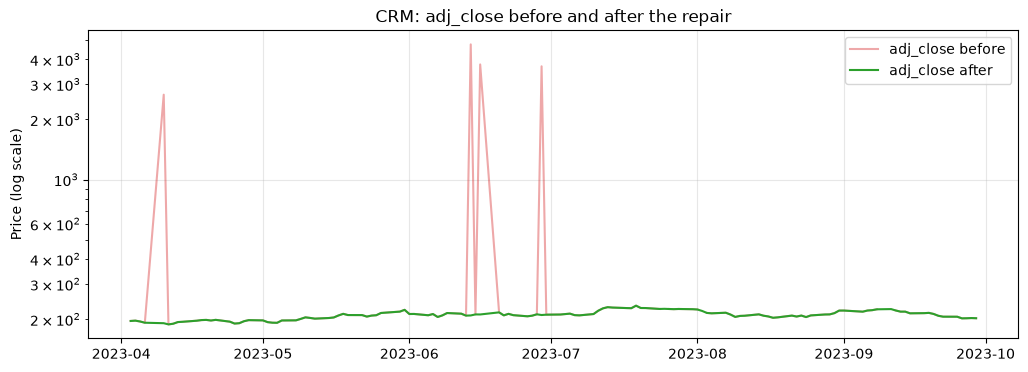

In [29]:
fig, ax = plt.subplots(figsize=(12, 4))
after = cleaned[cleaned["ticker"] == "CRM"].set_index("ts").loc["2023-04":"2023-09"]
ax.plot(example.index, example["adj_close"], label="adj_close before", color="tab:red", alpha=0.4)
ax.plot(after.index, after["adj_close"], label="adj_close after", color="tab:green")
ax.set_yscale("log")
ax.set_title("CRM: adj_close before and after the repair")
ax.set_ylabel("Price (log scale)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## Save the results

Dates are stored as ISO `YYYY-MM-DD` text so the report's SQL date filters work, and flags as 0/1 integers.
Four tables are written to the local working copy; the raw `ohlc_hw` table is untouched:

- `ohlc_hw_cleaned`: the cleaned data, with repair flags, `adj_source` and `return_outlier_class`
- `ohlc_hw_quarantine`: quarantined rows and the reason for each
- `ohlc_hw_quality_report`: the Data Quality Report (the diagnosis before repairs)
- `ohlc_hw_ticker_audit`: original ticker labels and the symbol each was normalized to

In [30]:
def to_iso(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """Copy of df with a datetime column formatted as YYYY-MM-DD text."""
    return df.assign(**{col: pd.to_datetime(df[col]).dt.strftime("%Y-%m-%d")})


CLEAN_COLUMNS = ["ts", "ticker", *ALL_PRICE_COLS, "volume", "adj_source", *flag_cols, "return_outlier_class"]
clean_out = to_iso(cleaned[CLEAN_COLUMNS], "ts")
clean_out[flag_cols] = clean_out[flag_cols].astype(int)
quarantine_out = to_iso(set_aside_rows.loc[set_aside_rows["action"] == "quarantined", [*RAW_COLUMNS, "reason", "step"]], "ts")
report_out = to_iso(quality_report, "issue_date").assign(severity=quality_report["severity"].astype(str))

with closing(sqlite3.connect(DB_PATH)) as conn:
    clean_out.to_sql(CLEAN_TABLE, conn, if_exists="replace", index=False)
    quarantine_out.to_sql(QUARANTINE_TABLE, conn, if_exists="replace", index=False)
    report_out.to_sql(REPORT_TABLE, conn, if_exists="replace", index=False)
    ticker_audit.to_sql(AUDIT_TABLE, conn, if_exists="replace", index=False)
    conn.execute(f"CREATE INDEX IF NOT EXISTS idx_{CLEAN_TABLE}_ticker_ts ON {CLEAN_TABLE} (ticker, ts)")
    conn.commit()
    non_iso = conn.execute(f"SELECT COUNT(*) FROM {CLEAN_TABLE} "
                           "WHERE ts NOT GLOB '[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]'").fetchone()[0]

# Read the table back and validate what was actually saved
saved = read_sql(f"SELECT * FROM {CLEAN_TABLE}")
validate_clean(saved)
assert non_iso == 0, f"{non_iso} dates are not stored as YYYY-MM-DD"
print(f"Saved {len(saved):,} rows for {saved['ticker'].nunique()} tickers to {CLEAN_TABLE}, "
      f"{saved['ts'].min():%Y-%m-%d} to {saved['ts'].max():%Y-%m-%d}; {len(quarantine_out)} rows quarantined")
saved.head()

Saved 368,251 rows for 30 tickers to ohlc_hw_cleaned, 1962-01-02 to 2024-12-06; 0 rows quarantined


,ts,ticker,open,high,low,close,adj_close,volume,adj_source,flag_price_invalid,flag_price_filled,flag_volume_filled,flag_close_repaired,flag_open_repaired,flag_bounds_fixed,flag_adj_repaired,flag_zero_volume,flag_weekend,flag_return_outlier,return_outlier_class
0,1980-12-12,AAPL,0.12835,0.12835,0.12835,0.12835,0.098941,469034068,original,0,0,0,0,0,0,0,0,0,0,
1,1980-12-15,AAPL,0.12165,0.12165,0.12165,0.12165,0.093779,175884971,original,0,0,0,0,0,0,0,0,0,0,
2,1980-12-16,AAPL,0.11272,0.11272,0.11272,0.11272,0.086896,105728103,original,0,0,0,0,0,0,0,0,0,0,
3,1980-12-17,AAPL,0.11551,0.11551,0.11551,0.11551,0.089046,86441684,original,0,0,0,0,0,0,0,0,0,0,
4,1980-12-18,AAPL,0.11886,0.11886,0.11886,0.11886,0.091627,73449671,original,0,0,0,0,0,0,0,0,0,0,


## Summary

- **Structural problems were the biggest issue:** 30 stocks stored under 150 labels, plus about 29k exact
  duplicate rows. Normalizing labels before de-duplicating keeps the ~10% of observations that existed only under
  an HTML label.
- **`adj_close` was the main deliberate corruption:** missing values and about 10k values inflated 4–24×. Each was
  rebuilt from the raw close and a *validated* adjustment factor, keeping the adjustment convention consistent.
  Rows without a defensible factor would have been quarantined.
- **Raw prices were mostly sound:** three one-day TRV spikes were interpolated and five zero opens estimated.
  Everything else was kept and flagged. No missing trading days were found against the reference calendar.
- **Extreme returns were kept:** fat tails are real. Each one is flagged and classified, and the claims about
  causes are limited to what the data supports.
- **Testing:** the injected-fault tests show the detectors and repairs working on the cases this database lacks.
  The cleaned table passes every validation check, and every raw row is accounted for.